# 01 · Data Preparation (shared by all four algorithms)

**Team clustering project: K-Means · DBSCAN · Hierarchical · GMM**

This notebook turns the raw invoice lines of an online gift retailer into **one row per customer**, then prepares those rows for clustering. All four algorithms read the files saved at the end. They therefore cluster the same customers with the same features in the same order, so any difference between the results comes from the algorithms.

| Step | What happens |
|---|---|
| 1-2 | setup and loading the raw data |
| 3 | cleaning |
| 4 | building 12 features per customer |
| 5 | setting aside the 5% most extreme customers |
| 6 | Yeo-Johnson transform and standardisation |
| 7 | PCA to 5 components |
| 8 | saving the files each teammate uses |

**Data:** the Online Retail transactions (UK online retailer, 01/12/2010 to 09/12/2011), as used in the Kaggle notebook [Customer Segmentation & Recommendation System](https://www.kaggle.com/code/farzadnekouei/customer-segmentation-recommendation-system). The original source is the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/352/online+retail) (Chen, Sain & Guo, 2012).

**Acknowledgement:** the cleaning checks, the customer features and the use of Isolation Forest and PCA are adapted from Farzad Nekouee's notebook above. We trimmed it and changed several choices, each explained where it happens.

## 1. Setup
This notebook lives in the `data/` folder and runs from there. It reads the compressed raw file `raw/data.csv.gz` (7.5 MB instead of 45 MB) and writes the prepared files to `processed/`. `RANDOM_STATE` is fixed so everyone gets identical files.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import PowerTransformer
from sklearn.decomposition import PCA

DATA_PATH = "raw/data.csv.gz"     # Online Retail export (541,909 rows), gzip-compressed
OUT_DIR = Path("processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
DIVERGING = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlelocation": "left", "axes.titlesize": 12, "font.size": 10, "figure.dpi": 110,
    "axes.axisbelow": True,
})
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## 2. Load the data
Each row is one product line on one invoice. Invoice numbers starting with **C** are cancellations, and their quantities are negative.

In [2]:
df_raw = pd.read_csv(DATA_PATH, encoding="ISO-8859-1", compression="gzip",
                     dtype={"InvoiceNo": str, "StockCode": str})
print(f"{len(df_raw):,} rows x {df_raw.shape[1]} columns")
display(df_raw.head())

missing = df_raw.isna().mean().mul(100).round(2)
missing[missing > 0].to_frame("missing %")

541,909 rows x 8 columns


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom


,missing %
Description,0.27
CustomerID,24.93


541,909 invoice lines and 8 columns. Two columns have gaps: **24.93%** of lines have no `CustomerID` and **0.27%** have no product description.

## 3. Cleaning
One pass, logging how many rows each rule removes:

1. **No `CustomerID` or `Description`**: we cluster customers, so anonymous rows cannot be used, and filling in an ID would invent customers.
2. **Exact duplicates**: same invoice, product, quantity and timestamp. These are recording errors, not repeat purchases.
3. **Non-product rows**: stock codes with fewer than two digits (`POST`, `M`, `D`, `BANK CHARGES`, …) are postage, fees and manual adjustments, and two service lines are not products either.
4. **Zero unit price**: a handful of rows that look like data-entry errors.

Cancellations are **kept** but flagged, because how often a customer cancels is useful information.

In [3]:
log = [("raw data", len(df_raw))]

df = df_raw.dropna(subset=["CustomerID", "Description"]).copy()
log.append(("no CustomerID or Description", len(df)))

df = df.drop_duplicates()
log.append(("exact duplicate rows", len(df)))

non_product = (df["StockCode"].str.count(r"\d") < 2) | \
              df["Description"].isin(["Next Day Carriage", "High Resolution Image"])
removed_codes = sorted(df.loc[non_product, "StockCode"].unique())
df = df[~non_product]
log.append(("postage, fees and other non-product rows", len(df)))

df = df[df["UnitPrice"] > 0].copy()
log.append(("zero unit price", len(df)))

df["CustomerID"] = df["CustomerID"].astype(int)
df["Description"] = df["Description"].str.upper().str.strip()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], format="%m/%d/%Y %H:%M")
df["IsCancelled"] = df["InvoiceNo"].str.startswith("C")
df["Amount"] = df["Quantity"] * df["UnitPrice"]

cleaning_log = pd.DataFrame(log, columns=["removed because", "rows left"])
cleaning_log["rows removed"] = (-cleaning_log["rows left"].diff()).fillna(0).astype(int)
print("non-product codes removed:", removed_codes)
print(f"customers: {df['CustomerID'].nunique():,} | cancelled lines: {df['IsCancelled'].mean():.1%}")
cleaning_log

non-product codes removed: ['23444', '23702', 'BANK CHARGES', 'C2', 'CRUK', 'D', 'DOT', 'M', 'PADS', 'POST']
customers: 4,362 | cancelled lines: 2.1%


,removed because,rows left,rows removed
0,raw data,541909,0
1,no CustomerID or Description,406829,135080
2,exact duplicate rows,401604,5225
3,"postage, fees and other non-product rows",399606,1998
4,zero unit price,399573,33


Dropping anonymous lines is by far the largest cut (135,080 rows). The other three rules together remove fewer than 7,300. We are left with **399,573 lines from 4,362 customers**, and 2.1% of those lines are cancellations.

## 4. From invoice lines to customers
Clustering needs one row per customer. We summarise each customer's year with 12 numbers:

| feature | meaning |
|---|---|
| `Recency_Days` | days between the customer's last purchase and the last day in the data |
| `N_Invoices` | number of distinct invoices (purchases and cancellations) |
| `Total_Quantity` | items bought, net of returns |
| `Total_Spend` | money spent, net of returns (£) |
| `Unique_Products` | how many different products the customer bought |
| `Avg_Invoice_Value` | `Total_Spend / N_Invoices` |
| `Avg_Days_Between_Purchases` | average gap between distinct purchase days (0 when they bought on a single day) |
| `N_Cancellations` | number of cancelled invoices |
| `Cancellation_Rate` | `N_Cancellations / N_Invoices` |
| `Monthly_Spend_Mean` / `Monthly_Spend_Std` | average and spread of spending across the months they were active |
| `Spend_Trend` | slope of monthly spending over calendar months (£ per month; negative = spending less over time) |

Differences from the original pipeline, and why:
- **Purchase gaps** use distinct purchase *days*. Averaging over individual invoice lines counts the many zero-day gaps between lines of the same invoice.
- **Spending trend** uses the real calendar month, so a gap of several months is not treated as one step.
- **Favourite weekday and hour are dropped.** They are categories stored as numbers, so they would tell a distance-based method that Monday (0) is far from Sunday (6).
- **Country** is kept only to describe clusters afterwards (about 90% of customers are in the UK).

In [4]:
last_day = df["InvoiceDate"].dt.normalize().max()
df["Day"] = df["InvoiceDate"].dt.normalize()
df["MonthIdx"] = (df["InvoiceDate"].dt.year - 2010) * 12 + df["InvoiceDate"].dt.month

g = df.groupby("CustomerID")
customers = pd.DataFrame({
    "Recency_Days": (last_day - g["Day"].max()).dt.days,
    "N_Invoices": g["InvoiceNo"].nunique(),
    "Total_Quantity": g["Quantity"].sum(),
    "Total_Spend": g["Amount"].sum(),
    "Unique_Products": g["StockCode"].nunique(),
})
customers["Avg_Invoice_Value"] = customers["Total_Spend"] / customers["N_Invoices"]

buy_days = df[~df["IsCancelled"]].groupby("CustomerID")["Day"].agg(["min", "max", "nunique"])
gap = (buy_days["max"] - buy_days["min"]).dt.days / (buy_days["nunique"] - 1)
customers["Avg_Days_Between_Purchases"] = gap.where(buy_days["nunique"] > 1, 0).reindex(customers.index).fillna(0)

customers["N_Cancellations"] = (df[df["IsCancelled"]].groupby("CustomerID")["InvoiceNo"].nunique()
                                .reindex(customers.index).fillna(0))
customers["Cancellation_Rate"] = customers["N_Cancellations"] / customers["N_Invoices"]

monthly = df.groupby(["CustomerID", "MonthIdx"])["Amount"].sum().reset_index()
customers["Monthly_Spend_Mean"] = monthly.groupby("CustomerID")["Amount"].mean()
customers["Monthly_Spend_Std"] = monthly.groupby("CustomerID")["Amount"].std().fillna(0)

def spend_slope(m):
    return np.polyfit(m["MonthIdx"], m["Amount"], 1)[0] if len(m) > 1 else 0.0

customers["Spend_Trend"] = monthly.groupby("CustomerID")[["MonthIdx", "Amount"]].apply(spend_slope)

main_country = (df.groupby(["CustomerID", "Country"]).size().rename("n").reset_index()
                .sort_values("n", ascending=False).drop_duplicates("CustomerID")
                .set_index("CustomerID")["Country"])
customers["Country"] = main_country

FEATURES = [c for c in customers.columns if c != "Country"]
assert customers[FEATURES].notna().all().all()
print(f"{len(customers):,} customers x {len(FEATURES)} features")
customers[FEATURES].describe(percentiles=[0.5, 0.95]).T[["mean", "50%", "95%", "max"]]

4,362 customers x 12 features


,mean,50%,95%,max
Recency_Days,91.71,50.00,313.00,373.00
N_Invoices,4.99,3.00,16.00,242.00
Total_Quantity,"1,117.38",365.00,"3,458.40","196,556.00"
Total_Spend,"1,894.60",641.78,"5,613.41","278,778.02"
Unique_Products,61.17,35.00,203.85,"1,791.00"
Avg_Invoice_Value,320.76,236.96,772.18,"9,904.88"
Avg_Days_Between_Purchases,50.15,30.72,183.00,366.00
N_Cancellations,0.78,0.00,4.00,45.00
Cancellation_Rate,0.11,0.00,0.50,1.00
Monthly_Spend_Mean,450.61,304.38,"1,084.73","39,619.50"


The typical customer is small, with a median of 3 invoices and about £640 spent, while the largest are hundreds of times bigger (242 invoices, £278,778). Many features are also **exactly zero** for large groups of customers. One-time buyers have no purchase gap and no month-to-month spread, and most customers never cancel. Each algorithm notebook should keep both facts in mind.

## 5. Setting aside extreme customers
A few customers buy at a completely different scale from everyone else. An **Isolation Forest** flags the most isolated 5%, and the main clustering file leaves them out.

They are not deleted. `customer_pca_all.csv` (Step 8) includes them, placed in exactly the same space as everyone else, so each algorithm can test how it reacts to them. This matters most for DBSCAN, which has its own way of labelling noise.

In [5]:
iso = IsolationForest(contamination=0.05, random_state=RANDOM_STATE)
customers["IsOutlier"] = iso.fit_predict(customers[FEATURES]) == -1

clean = customers[~customers["IsOutlier"]].copy()
outliers = customers[customers["IsOutlier"]].copy()
print(f"set aside: {len(outliers)} customers | kept for clustering: {len(clean):,}")

pd.DataFrame({"typical customer (median)": clean[FEATURES].median(),
              "set-aside customer (median)": outliers[FEATURES].median()})

set aside: 219 customers | kept for clustering: 4,143


,typical customer (median),set-aside customer (median)
Recency_Days,51.00,10.00
N_Invoices,2.00,16.00
Total_Quantity,342.00,"4,823.00"
Total_Spend,605.12,"8,568.24"
Unique_Products,34.00,119.00
Avg_Invoice_Value,230.51,595.50
Avg_Days_Between_Purchases,32.00,21.59
N_Cancellations,0.00,3.00
Cancellation_Rate,0.00,0.21
Monthly_Spend_Mean,295.44,"1,336.26"


The 219 set-aside customers (5%) are the heavy accounts: a median of 16 invoices and £8,568 spent, against 2 invoices and £605 for a typical customer. They are unusual customers rather than broken rows, which is why they are kept in a separate file instead of being thrown away.

## 6. Making the features comparable
Two problems remain:
- **Very different units.** Pounds, days and counts would dominate each other.
- **Very long right tails.** Most customers spend a few hundred pounds, and a few spend tens of thousands.

Distance-based methods (K-Means, DBSCAN, Hierarchical) would be dominated by those few huge values, and GMM assumes bell-shaped clusters. We therefore use a **Yeo-Johnson power transform**. It works like a log but also accepts the zeros and negative values found in spend and trend, and it then standardises every feature to mean 0 and standard deviation 1.

The transform is **fitted on the regular customers only** and then applied to the set-aside ones, so all customers live in the same space.

In [6]:
power = PowerTransformer(method="yeo-johnson", standardize=True)
X = pd.DataFrame(power.fit_transform(clean[FEATURES]), index=clean.index, columns=FEATURES)

pd.DataFrame({"skew before": clean[FEATURES].skew(), "skew after": X.skew()}).round(2)

,skew before,skew after
Recency_Days,1.22,-0.06
N_Invoices,2.92,0.17
Total_Quantity,2.94,0.10
Total_Spend,2.54,0.25
Unique_Products,2.38,-0.02
Avg_Invoice_Value,2.68,1.10
Avg_Days_Between_Purchases,1.96,-0.13
N_Cancellations,2.76,0.77
Cancellation_Rate,1.79,0.84
Monthly_Spend_Mean,2.16,0.88


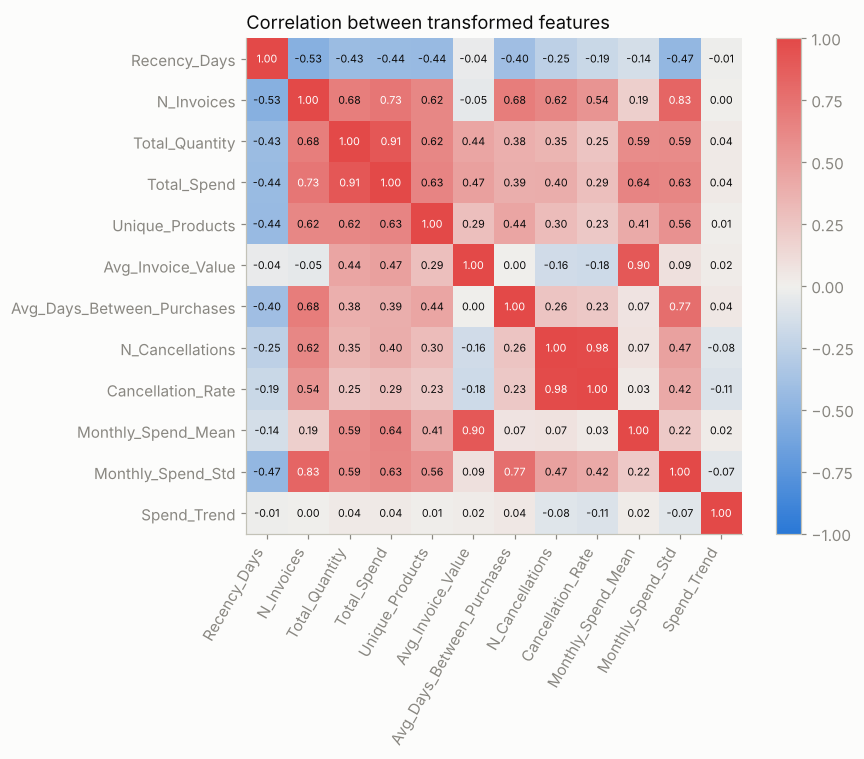

In [7]:
corr = X.corr()
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=60, ha="right")
ax.set_yticks(range(len(FEATURES)), FEATURES)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(v) > 0.7 else INK)
ax.grid(False)
ax.set_title("Correlation between transformed features")
fig.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout(); plt.show()

After the transform, every feature is close to symmetric (skew mostly between -0.2 and 1.1). The one exception is `Spend_Trend` (2.3), because more than a third of the customers (those active in a single month) have a trend of exactly 0. Three pairs of features almost duplicate each other:
- `N_Cancellations` and `Cancellation_Rate`: 0.98
- `Total_Quantity` and `Total_Spend`: 0.91
- `Avg_Invoice_Value` and `Monthly_Spend_Mean`: 0.90

Keeping both features of a pair would count the same idea twice. PCA in the next step merges them into shared components.

## 7. Dimensionality reduction with PCA
**PCA** rotates the 12 features into uncorrelated components ordered by how much variation they explain. We keep the smallest number of components that explains **at least 85%** of the variation.

This helps every algorithm:
- Distances are clearer in fewer dimensions (K-Means, DBSCAN, Hierarchical).
- GMM needs far fewer parameters.
- PC1 and PC2 give everyone the same 2D view for their plots.

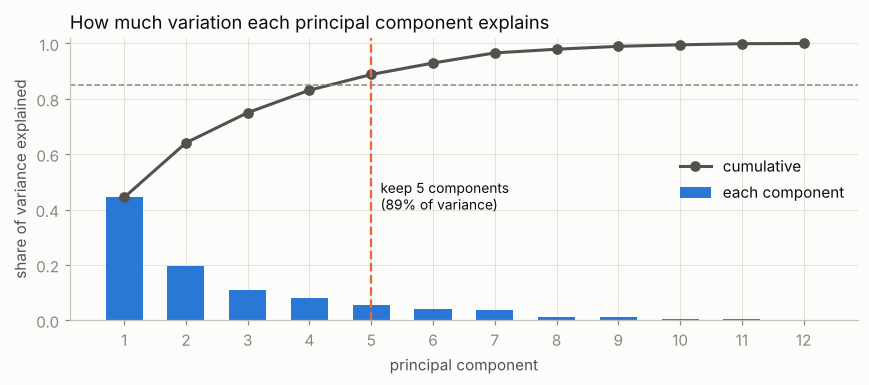

cumulative variance: [0.444 0.641 0.75  0.831 0.888]


In [8]:
pca_all = PCA().fit(X)
cumvar = np.cumsum(pca_all.explained_variance_ratio_)
N_COMPONENTS = int(np.argmax(cumvar >= 0.85) + 1)

fig, ax = plt.subplots(figsize=(8, 3.6))
pcs = np.arange(1, len(cumvar) + 1)
ax.bar(pcs, pca_all.explained_variance_ratio_, color=COLORS[0], width=0.6, label="each component")
ax.plot(pcs, cumvar, color=INK2, marker="o", lw=2, label="cumulative")
ax.axhline(0.85, color=MUTED, ls="--", lw=1)
ax.axvline(N_COMPONENTS, color=COLORS[1], ls="--", lw=1.5)
ax.text(N_COMPONENTS + 0.15, 0.40, f"keep {N_COMPONENTS} components\n({cumvar[N_COMPONENTS-1]:.0%} of variance)",
        color=INK, fontsize=9)
ax.set_xticks(pcs); ax.set_xlabel("principal component"); ax.set_ylabel("share of variance explained")
ax.set_ylim(0, 1.02); ax.legend(frameon=False, loc="center right")
ax.set_title("How much variation each principal component explains")
plt.tight_layout(); plt.show()

pca = PCA(n_components=N_COMPONENTS)
Z = pd.DataFrame(pca.fit_transform(X), index=X.index,
                 columns=[f"PC{i+1}" for i in range(N_COMPONENTS)])
print("cumulative variance:", np.round(cumvar[:N_COMPONENTS], 3))

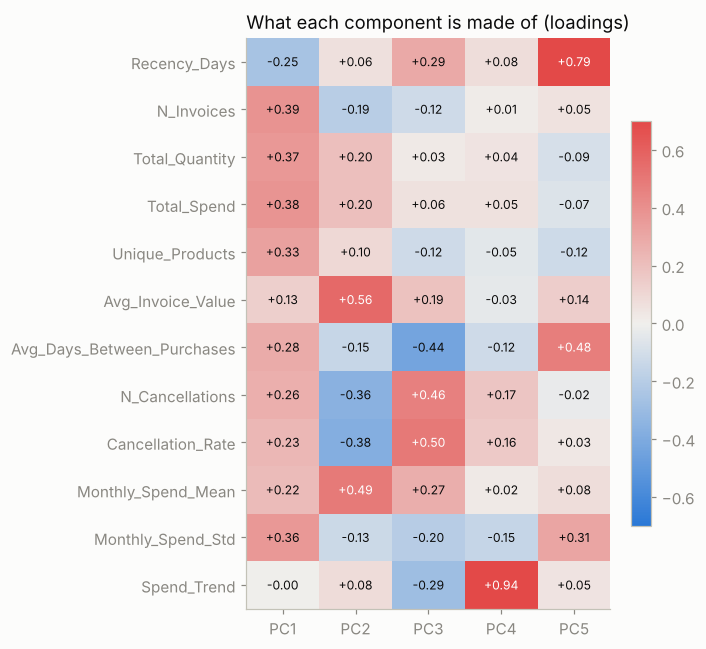

In [9]:
loadings = pd.DataFrame(pca.components_.T, index=FEATURES, columns=Z.columns)
fig, ax = plt.subplots(figsize=(6.5, 6))
im = ax.imshow(loadings, cmap=DIVERGING, vmin=-0.7, vmax=0.7, aspect="auto")
ax.set_xticks(range(N_COMPONENTS), Z.columns); ax.set_yticks(range(len(FEATURES)), FEATURES)
for i in range(len(FEATURES)):
    for j in range(N_COMPONENTS):
        ax.text(j, i, f"{loadings.iloc[i, j]:+.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(loadings.iloc[i, j]) > 0.45 else INK)
ax.grid(False); ax.set_title("What each component is made of (loadings)")
fig.colorbar(im, ax=ax, fraction=0.05); plt.tight_layout(); plt.show()

**5 components keep 89% of the variation.** The loadings tell us what each one means:
- **PC1 (44%)**: overall activity. Invoices, items, spend and product range all point the same way.
- **PC2 (20%)**: basket size (average invoice value, monthly spend) against cancellations.
- **PC3**: cancellations against long gaps between purchases.
- **PC4**: almost only the spending trend.
- **PC5**: recency, meaning how long ago the last purchase was.

## 8. Saving the files
| file | rows | what it is | who uses it |
|---|---|---|---|
| `customer_pca.csv` | 4,143 | **the main clustering input**: 5 PCA components of the regular customers | everyone |
| `customer_features.csv` | 4,362 | the 12 readable features, `Country` and `IsOutlier` for all customers | everyone, to describe clusters |
| `customer_pca_all.csv` | 4,362 | the same 5 components **including** the set-aside customers, with an `IsOutlier` column; regular customers have exactly the values in `customer_pca.csv` | DBSCAN and GMM noise tests (optional for the others) |
| `customer_features_transformed.csv` | 4,143 | the 12 features after Yeo-Johnson, before PCA | optional side experiment: does skipping PCA change your result? |

All files go to `data/processed/`. Every file is indexed by `CustomerID`, and the rows of the regular customers come in the same order everywhere.

In [10]:
# set-aside customers projected with the transform and PCA fitted on regular customers
X_out = pd.DataFrame(power.transform(outliers[FEATURES]), index=outliers.index, columns=FEATURES)
Z_out = pd.DataFrame(pca.transform(X_out), index=outliers.index, columns=Z.columns)
Z_all = pd.concat([Z, Z_out]).loc[customers.index]
Z_all["IsOutlier"] = customers["IsOutlier"]

Z.to_csv(OUT_DIR / "customer_pca.csv", index_label="CustomerID")
customers.to_csv(OUT_DIR / "customer_features.csv", index_label="CustomerID")
Z_all.to_csv(OUT_DIR / "customer_pca_all.csv", index_label="CustomerID")
X.to_csv(OUT_DIR / "customer_features_transformed.csv", index_label="CustomerID")

# checks
check = pd.read_csv(OUT_DIR / "customer_pca.csv", index_col="CustomerID")
check_all = pd.read_csv(OUT_DIR / "customer_pca_all.csv", index_col="CustomerID")
assert check.notna().all().all() and check.index.is_unique and len(check) == len(clean)
assert np.allclose(check_all.loc[check.index, Z.columns].values, check.values)
assert (check_all["IsOutlier"].sum() == len(outliers))
for f in sorted(OUT_DIR.iterdir()):
    d = pd.read_csv(f, index_col="CustomerID")
    print(f"{f.name:<36} {d.shape[0]:>5} rows x {d.shape[1]:>2} columns")

customer_features.csv                 4362 rows x 14 columns
customer_features_transformed.csv     4143 rows x 12 columns
customer_pca.csv                      4143 rows x  5 columns
customer_pca_all.csv                  4362 rows x  6 columns


## How to load the data in your notebook
Each algorithm has its own folder (`kmeans/`, `dbscan/`, `hierarchical/`, `gmm/`) with a README. A notebook saved in one of those folders loads the data like this:
```python
import pandas as pd
Z = pd.read_csv("../data/processed/customer_pca.csv", index_col="CustomerID")              # cluster this
info = pd.read_csv("../data/processed/customer_features.csv", index_col="CustomerID").loc[Z.index]  # describe with this
```
Rules for a fair comparison:
1. **Do not rescale** `customer_pca.csv`. It is already prepared, and rescaling would make PC5 as important as PC1.
2. **Cluster on the PCA file, but describe clusters with `customer_features.csv`.** "High spend" means something to a reader, while "high PC3" does not.
3. **Save your labels** in your own folder as `labels_<algorithm>.npy`, in the row order of `customer_pca.csv`. DBSCAN keeps noise as `-1`.
4. Report the same things: number of clusters, cluster sizes, silhouette (DBSCAN: without noise, plus the noise share), Davies-Bouldin, how the clusters look on PC1/PC2, and how sensitive the method is to noise.